# Credit risk model: will a client default?

The bank wants to know the risk that a client will not pay back a credit (default). For every client there is their credit history from the credit bureau: one row per credit, about 26 million credits for 3 million clients. The target `flag` is 1 if the client went into default.

Goal: ROC-AUC on the test set of at least 0.75, a sklearn pipeline that prepares the data and trains the model by `fit` and makes predictions by `predict`, trained on all data and saved in pickle.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, f1_score
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

import warnings
warnings.filterwarnings('ignore')

# smaller pictures, otherwise the notebook gets heavy
plt.rcParams['figure.dpi'] = 72

DATA_PATH = 'data/train_data'
TARGET_PATH = 'data/train_target.csv'
N_FILES = 12

## 1. What the data looks like

The data is in 12 parquet files. All of them together do not fit in memory comfortably, so first I look at one file.

In [2]:
first_file = pd.read_parquet(f'{DATA_PATH}/train_data_0.pq')
print(first_file.shape)
first_file.head()

(1974724, 61)


,id,rn,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,0,1,18,9,2,3,16,10,11,3,...,3,3,3,4,1,3,4,1,0,0
1,0,2,18,9,14,14,12,12,0,3,...,0,0,0,4,1,3,4,1,0,0
2,0,3,18,9,4,8,1,11,11,0,...,0,0,0,4,1,2,3,1,1,1
3,0,4,4,1,9,12,16,7,12,2,...,3,3,3,4,1,3,1,1,0,0
4,0,5,5,12,15,2,11,12,10,2,...,3,3,3,4,1,3,4,1,0,0


In [3]:
print(first_file.dtypes.value_counts())
print('memory, MB:', round(first_file.memory_usage().sum() / 1e6))
print('clients:', first_file['id'].nunique(), '| ids from', first_file['id'].min(), 'to', first_file['id'].max())
print('credits per client: mean', round(len(first_file) / first_file['id'].nunique(), 1), '| max', first_file['rn'].max())
print('missing values:', first_file.isna().sum().sum())
first_file.drop(columns=['id', 'rn']).nunique().describe().round(1)

int64    61
Name: count, dtype: int64
memory, MB: 964
clients: 250000 | ids from 0 to 249999
credits per client: mean 7.9 | max 51
missing values: 0


count    59.0
mean      6.7
std       5.9
min       1.0
25%       4.0
50%       4.0
75%       7.0
max      20.0
dtype: float64

In [4]:
target = pd.read_csv(TARGET_PATH)
print(target.shape)
print(target['flag'].value_counts())
print('share of defaults:', round(target['flag'].mean(), 4))

(3000000, 2)
flag
0    2893558
1     106442
Name: count, dtype: int64
share of defaults: 0.0355


What I see:
- one row is one credit of a client, `rn` is the number of the credit in the history, so one client has several rows. The model has to predict for a client, so the credits have to be turned into one row per client;
- one file has exactly 250,000 clients in a row of ids, so files can be processed one by one;
- every column is already cut into bins and the bins got random numbers (from the methodology), so the numbers have no order. That is why I treat all columns as categories, not as numbers;
- all values are small (at most 20 different bins in a column) but they are stored as int64. int8 takes 8 times less memory;
- no missing values;
- only 3.55% of clients defaulted, the classes are very imbalanced. That is fine for ROC-AUC, it does not depend on the share of classes.

## 2. Features

I read the files one by one, make features for the clients of that file and keep only the features. Which features and why:
- counts of each bin of each column: for every client how many of their credits are in this bin. For example how many credits have an overdue of more than 90 days or how many are closed. This keeps almost all information of the history and works for any number of credits;
- `n_credits`: number of credits. A long history means the client already got and paid credits;
- `n_overdue_credits` and `share_overdue_credits`: how many credits had any overdue (one of the `is_zero_loans*` flags is 0) and what share of all credits it is. Overdues in the past are the most direct sign of risk;
- `paym_status_k_total`: how many times each payment status appears in all months of all credits, a short summary of payment discipline;
- `last_*`: status, type, age, utilization and the last payment of the newest credit (biggest `rn`). The newest credit says more about the current situation than old ones.

In [5]:
# flag = 0 means the credit had an overdue of this length
OVERDUE_FLAGS = ['is_zero_loans5', 'is_zero_loans530', 'is_zero_loans3060', 'is_zero_loans6090', 'is_zero_loans90']
PAYM_COLS = [f'enc_paym_{i}' for i in range(25)]
LAST_CREDIT_COLS = ['enc_loans_credit_status', 'enc_loans_credit_type', 'pre_since_opened', 'pre_util', 'enc_paym_0']


def read_records(path):
    records = pd.read_parquet(path)
    feature_cols = [col for col in records.columns if col not in ('id', 'rn')]
    records[feature_cols] = records[feature_cols].astype('int8')
    records['id'] = records['id'].astype('int32')
    records['rn'] = records['rn'].astype('int16')
    return records


def make_features(records):
    feature_cols = [col for col in records.columns if col not in ('id', 'rn')]
    ids = records['id']

    # counts of credits in each bin of each column
    dummies = pd.get_dummies(records[feature_cols], columns=feature_cols, dtype='uint8')
    dummies['id'] = ids.values
    features = dummies.groupby('id').sum()

    features['n_credits'] = ids.value_counts().sort_index().astype('int16')
    has_overdue = (records[OVERDUE_FLAGS] == 0).any(axis=1)
    features['n_overdue_credits'] = has_overdue.groupby(ids).sum().astype('int16')
    features['share_overdue_credits'] = (features['n_overdue_credits'] / features['n_credits']).astype('float32')
    for status in range(5):
        status_count = (records[PAYM_COLS] == status).sum(axis=1)
        features[f'paym_status_{status}_total'] = status_count.groupby(ids).sum().astype('int16')

    # the newest credit of each client
    last = records.sort_values(['id', 'rn']).groupby('id').tail(1).set_index('id')[LAST_CREDIT_COLS]
    last = pd.get_dummies(last, columns=LAST_CREDIT_COLS, prefix=['last_' + col for col in LAST_CREDIT_COLS],
                          dtype='uint8')
    return features.join(last)

In [6]:
start = time.time()
parts = []
for i in range(N_FILES):
    records = read_records(f'{DATA_PATH}/train_data_{i}.pq')
    parts.append(make_features(records))
    print(f'file {i}: credits {len(records)}, clients {records["id"].min()}-{records["id"].max()}, {time.time() - start:.0f} s')

features = pd.concat(parts)
# a bin can be missing in one file, after concat it becomes NaN
missing = features.columns[features.isna().any()]
features[missing] = features[missing].fillna(0).astype('uint8')
del parts, records

print(features.shape)
print('memory, MB:', round(features.memory_usage().sum() / 1e6))

file 0: credits 1974724, clients 0-249999, 4 s


file 1: credits 2107305, clients 250000-499999, 9 s


file 2: credits 2080508, clients 500000-749999, 13 s


file 3: credits 2112592, clients 750000-999999, 17 s


file 4: credits 2064110, clients 1000000-1249999, 21 s


file 5: credits 2150908, clients 1250000-1499999, 25 s


... (3 outputs left out)

file 9: credits 2284256, clients 2250000-2499999, 44 s


file 10: credits 2296372, clients 2500000-2749999, 48 s


file 11: credits 2450630, clients 2750000-2999999, 53 s


(3000000, 486)
memory, MB: 1500


In [7]:
# save, so the long part does not have to be repeated if the kernel dies
import os
os.makedirs('features', exist_ok=True)
features.to_parquet('features/features.parquet')

count_cols = [col for col in features.columns if '_' in col and col.rsplit('_', 1)[1].isdigit()
              and not col.startswith(('last_', 'paym_status_'))]
extra_cols = ['n_credits', 'n_overdue_credits', 'share_overdue_credits'] + [f'paym_status_{s}_total' for s in range(5)]
last_cols = [col for col in features.columns if col.startswith('last_')]
print('counts:', len(count_cols), '| extra:', len(extra_cols), '| last credit:', len(last_cols))

counts: 419 | extra: 8 | last credit: 59


## 3. Features + target

In [8]:
data = features.join(target.set_index('id'))
print(data.shape)
print('clients without target:', data['flag'].isna().sum())
del features

(3000000, 487)
clients without target: 0


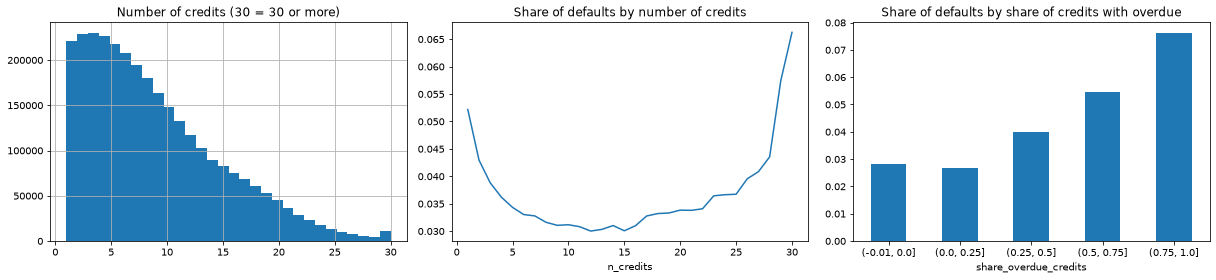

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

data['n_credits'].clip(upper=30).hist(bins=30, ax=axes[0])
axes[0].set_title('Number of credits (30 = 30 or more)')

data.groupby(data['n_credits'].clip(upper=30))['flag'].mean().plot(ax=axes[1])
axes[1].set_title('Share of defaults by number of credits')
axes[1].set_xlabel('n_credits')

overdue_groups = pd.cut(data['share_overdue_credits'], [-0.01, 0, 0.25, 0.5, 0.75, 1])
data.groupby(overdue_groups, observed=True)['flag'].mean().plot(kind='bar', ax=axes[2])
axes[2].set_title('Share of defaults by share of credits with overdue')
axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

What I see:
- most clients have 2 to 10 credits, the tail goes up to 51;
- the share of defaults by number of credits looks like a U: clients with 1 credit default more often (5.2%), the lowest is at 10-15 credits (about 3%), and after 25 credits it goes up again (6.6% at 30 and more). A short history means the bank knows little about the client, a very long one probably means the client lives on credits. The relation is not linear, so a tree model should do better than a linear one;
- the bigger the share of credits with overdue, the more often the client defaults: 2.8% without overdues, 4% when a quarter to a half of credits had one and 7.6% when more than 75% had one. So the overdue features make sense.

## 4. Train and test

80% of clients for training, 20% for the test. stratify keeps the same share of defaults in both. The test set is used only at the end.

In [10]:
X = data.drop(columns='flag')
y = data['flag'].astype('int8')
del data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
del X
print('train:', X_train.shape, '| test:', X_test.shape)
print('share of defaults: train', round(y_train.mean(), 4), '| test', round(y_test.mean(), 4))

train: (2400000, 486) | test: (600000, 486)
share of defaults: train 0.0355 | test 0.0355


## 5. Experiments with features

To compare quickly I take 600,000 clients from the train set and do 3-fold cross-validation with LightGBM with default parameters. Three sets of features:
1. counts of bins + number of credits;
2. the same + shares of bins (count divided by the number of credits), so that clients with a short and a long history are compared fairly;
3. counts + all extra features (overdues, payment statuses, the newest credit).

In [11]:
sample_idx = X_train.sample(600_000, random_state=42).index
X_sample, y_sample = X_train.loc[sample_idx], y_train.loc[sample_idx]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

shares = X_sample[count_cols].div(X_sample['n_credits'], axis=0).astype('float32').add_prefix('share_')
feature_sets = {
    '1. counts + n_credits': X_sample[count_cols + ['n_credits']],
    '2. counts + n_credits + shares': pd.concat([X_sample[count_cols + ['n_credits']], shares], axis=1),
    '3. counts + extra + newest credit': X_sample[count_cols + extra_cols + last_cols],
}

feature_results = []
for name, X_set in feature_sets.items():
    start = time.time()
    scores = cross_val_score(LGBMClassifier(random_state=42, verbose=-1), X_set, y_sample, cv=cv, scoring='roc_auc')
    feature_results.append({'features': name, 'columns': X_set.shape[1], 'cv roc_auc': scores.mean(),
                            'std': scores.std(), 'seconds': round(time.time() - start)})
    print(name, scores.round(4))
del shares, feature_sets
pd.DataFrame(feature_results).round(4)

1. counts + n_credits [0.7551 0.7435 0.7552]


2. counts + n_credits + shares [0.7518 0.7448 0.755 ]


3. counts + extra + newest credit [0.7553 0.7459 0.7555]


,features,columns,cv roc_auc,std,seconds
0,1. counts + n_credits,420,0.7513,0.0055,11
1,2. counts + n_credits + shares,839,0.7506,0.0043,22
2,3. counts + extra + newest credit,486,0.7522,0.0045,11


The differences are small, but set 3 is the best (0.7522 vs 0.7513 for counts only) and has the smallest spread between folds. The shares did not help (0.7506) and doubled the number of columns: once the number of credits is a feature, trees can work out the share themselves. I take set 3, 486 features.

## 6. Experiments with models

Same sample and the same cross-validation, feature set 3. Besides cross-validation each model is trained on the whole sample and checked on the test set, to see that the score on new clients is close to the cross-validation one.

In [12]:
final_cols = count_cols + extra_cols + last_cols
X_sample = X_sample[final_cols]

models = {
    'LogisticRegression': Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=300))]),
    'RandomForest': RandomForestClassifier(n_estimators=150, min_samples_leaf=50, max_features='sqrt',
                                           n_jobs=-1, random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
}

model_results = []
for name, model in models.items():
    start = time.time()
    scores = cross_val_score(model, X_sample, y_sample, cv=cv, scoring='roc_auc')
    model.fit(X_sample, y_sample)
    test_auc = roc_auc_score(y_test, model.predict_proba(X_test[final_cols])[:, 1])
    model_results.append({'model': name, 'cv roc_auc (train)': scores.mean(), 'roc_auc test': test_auc,
                          'seconds': round(time.time() - start)})
    print(name, round(scores.mean(), 4), round(test_auc, 4))
pd.DataFrame(model_results).round(4)

LogisticRegression 0.7365 0.737


RandomForest 0.7407 0.7385


HistGradientBoosting 0.7512 0.7523


LightGBM 0.7522 0.7537


,model,cv roc_auc (train),roc_auc test,seconds
0,LogisticRegression,0.7365,0.7370,16
1,RandomForest,0.7407,0.7385,130
2,HistGradientBoosting,0.7512,0.7523,72
3,LightGBM,0.7522,0.7537,16


- LightGBM is the best both on cross-validation (0.7522) and on the test (0.7537), and also the fastest (16 s for 3 folds + fit);
- HistGradientBoosting from sklearn is almost the same (0.7512 / 0.7523) but 4 times slower;
- RandomForest (0.7407) and LogisticRegression (0.7365) are clearly worse. Logistic regression sees every bin count only linearly, and the plots above show the relations are not linear;
- for every model cross-validation and test give almost the same numbers, so cross-validation on the sample is a fair way to compare.

So I tune LightGBM.

## 7. Hyperparameters of LightGBM

Now on the whole train set. 10% of it goes to validation: the model stops adding trees when the ROC-AUC on validation has not grown for 100 trees (early stopping), so the number of trees is chosen automatically. Learning rate 0.05, and I try a few settings from simple to more regularized:
- `num_leaves`: how big one tree is;
- `min_child_samples`: minimum clients in a leaf, protects from learning single clients;
- `colsample_bytree` and `subsample`: each tree sees only part of the features and clients;
- `reg_lambda`: L2 regularization of leaf values.

In [13]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train[final_cols], y_train, test_size=0.1, random_state=42,
                                              stratify=y_train)
print('fit:', X_fit.shape, '| validation:', X_val.shape)

param_grid = [
    {'num_leaves': 31, 'min_child_samples': 20, 'colsample_bytree': 1.0, 'subsample': 1.0, 'subsample_freq': 0, 'reg_lambda': 0.0},
    {'num_leaves': 63, 'min_child_samples': 100, 'colsample_bytree': 0.5, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 1.0},
    {'num_leaves': 127, 'min_child_samples': 300, 'colsample_bytree': 0.3, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 5.0},
    {'num_leaves': 255, 'min_child_samples': 1000, 'colsample_bytree': 0.3, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 10.0},
]

# for comparison: default parameters on the same split
default_model = LGBMClassifier(random_state=42, verbose=-1).fit(X_fit, y_fit)
tuning = [{'params': 'default (lr 0.1, 100 trees)', 'trees': 100,
           'roc_auc val': roc_auc_score(y_val, default_model.predict_proba(X_val)[:, 1]), 'seconds': None}]

for params in param_grid:
    start = time.time()
    model = LGBMClassifier(learning_rate=0.05, n_estimators=4000, random_state=42, verbose=-1, **params)
    model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], eval_metric='auc',
              callbacks=[early_stopping(100, verbose=False), log_evaluation(0)])
    tuning.append({'params': str(params), 'trees': model.best_iteration_,
                   'roc_auc val': roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),
                   'seconds': round(time.time() - start)})
    print(params, model.best_iteration_, round(tuning[-1]['roc_auc val'], 4))

tuning = pd.DataFrame(tuning)
pd.set_option('display.max_colwidth', 200)
tuning.round(4)

fit: (2160000, 486) | validation: (240000, 486)


{'num_leaves': 31, 'min_child_samples': 20, 'colsample_bytree': 1.0, 'subsample': 1.0, 'subsample_freq': 0, 'reg_lambda': 0.0} 1479 0.7573


{'num_leaves': 63, 'min_child_samples': 100, 'colsample_bytree': 0.5, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 1.0} 938 0.7605


{'num_leaves': 127, 'min_child_samples': 300, 'colsample_bytree': 0.3, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 5.0} 754 0.7619


{'num_leaves': 255, 'min_child_samples': 1000, 'colsample_bytree': 0.3, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 10.0} 613 0.7613


,params,trees,roc_auc val,seconds
0,"default (lr 0.1, 100 trees)",100,0.7518,NaN
1,"{'num_leaves': 31, 'min_child_samples': 20, 'colsample_bytree': 1.0, 'subsample': 1.0, 'subsample_freq': 0, 'reg_lambda': 0.0}",1479,0.7573,96.0
2,"{'num_leaves': 63, 'min_child_samples': 100, 'colsample_bytree': 0.5, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 1.0}",938,0.7605,241.0
3,"{'num_leaves': 127, 'min_child_samples': 300, 'colsample_bytree': 0.3, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 5.0}",754,0.7619,190.0
4,"{'num_leaves': 255, 'min_child_samples': 1000, 'colsample_bytree': 0.3, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 10.0}",613,0.7613,200.0


Default parameters give 0.7518 on validation, the best setting 0.7619, so tuning added about 0.01 of ROC-AUC. The winner is the third setting: bigger trees (127 leaves), but each tree sees only 30% of the features and 80% of the clients, at least 300 clients in a leaf and L2 = 5. With 2 million clients the model can afford bigger trees, but it needs the regularization so they don't learn noise. The biggest trees (255 leaves) are already a bit worse. Early stopping picked 754 trees.

In [14]:
best_row = tuning.iloc[1:]['roc_auc val'].idxmax()
best_params = param_grid[best_row - 1]
best_trees = int(tuning.loc[best_row, 'trees'])
print(best_params, '| trees:', best_trees)

# threshold for the 0/1 answer: the best F1 on validation, with the tuned model
tuned_on_fit = LGBMClassifier(learning_rate=0.05, n_estimators=best_trees, random_state=42, verbose=-1, **best_params)
tuned_on_fit.fit(X_fit, y_fit)
val_proba = tuned_on_fit.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.02, 0.5, 0.01).round(2)
f1s = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
threshold = thresholds[np.argmax(f1s)]
print('threshold:', threshold, '| f1 on validation:', round(max(f1s), 3))
del X_fit, X_val, tuned_on_fit

{'num_leaves': 127, 'min_child_samples': 300, 'colsample_bytree': 0.3, 'subsample': 0.8, 'subsample_freq': 1, 'reg_lambda': 5.0} | trees: 754


threshold: 0.1 | f1 on validation: 0.187


## 8. Final model and the test set

The tuned model is trained on the whole train set. For the summary table I also check it with the same 3-fold cross-validation on the 600,000 sample as the other models.

In [15]:
final_params = {'learning_rate': 0.05, 'n_estimators': best_trees, **best_params}

start = time.time()
cv_scores = cross_val_score(LGBMClassifier(random_state=42, verbose=-1, **final_params), X_sample, y_sample,
                            cv=cv, scoring='roc_auc')
print('cv roc_auc on the sample:', cv_scores.round(4), round(cv_scores.mean(), 4))

final_model = LGBMClassifier(random_state=42, verbose=-1, **final_params)
final_model.fit(X_train[final_cols], y_train)
test_proba = final_model.predict_proba(X_test[final_cols])[:, 1]
test_auc = roc_auc_score(y_test, test_proba)
print(f'ROC-AUC on the test set: {test_auc:.4f} ({time.time() - start:.0f} s)')
del X_sample

cv roc_auc on the sample: [0.7516 0.7428 0.7508] 0.7484


ROC-AUC on the test set: 0.7676 (352 s)


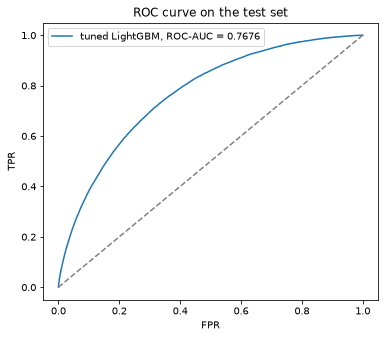

In [16]:
fpr, tpr, _ = roc_curve(y_test, test_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'tuned LightGBM, ROC-AUC = {test_auc:.4f}')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC curve on the test set')
plt.legend()
plt.show()

In [17]:
# is the score stable? ROC-AUC on 5 random parts of the test set
parts = np.array_split(np.random.RandomState(1).permutation(len(y_test)), 5)
print([round(roc_auc_score(y_test.iloc[p], test_proba[p]), 4) for p in parts])

[0.7623, 0.7713, 0.7741, 0.7657, 0.7647]


- ROC-AUC on the test set is 0.7676, above the required 0.75;
- on 5 random parts of the test set it is between 0.762 and 0.774, so the result doesn't depend on a lucky split;
- the test set was not used for any choice: features, models and parameters were chosen by cross-validation and validation inside the train set.

One thing to note: on the 600,000 sample the tuned parameters give a bit lower cross-validation (0.7484) than the default LightGBM (0.7522). The parameters were chosen for 2 million clients, and in a fold of 400,000 clients 754 big trees start to overfit. With all the train data they are clearly better: 0.7619 vs 0.7518 on the same validation, and 0.7676 on the test.

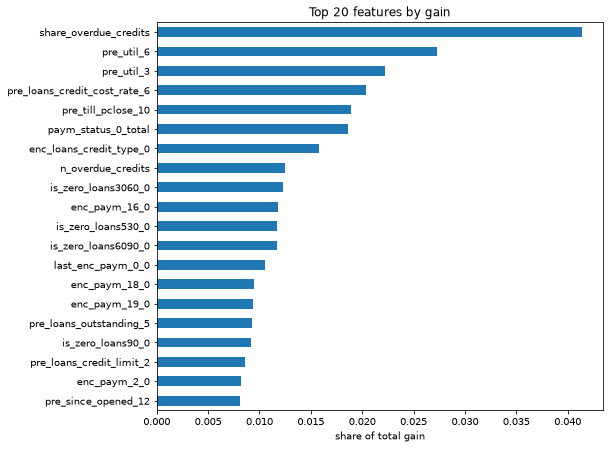

share_overdue_credits           0.041
pre_util_6                      0.027
pre_util_3                      0.022
pre_loans_credit_cost_rate_6    0.020
pre_till_pclose_10              0.019
paym_status_0_total             0.019
enc_loans_credit_type_0         0.016
n_overdue_credits               0.012
is_zero_loans3060_0             0.012
enc_paym_16_0                   0.012
dtype: float64

In [18]:
importance = pd.Series(final_model.booster_.feature_importance(importance_type='gain'), index=final_cols)
importance = (importance / importance.sum()).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
importance.head(20).sort_values().plot(kind='barh')
plt.title('Top 20 features by gain')
plt.xlabel('share of total gain')
plt.show()
importance.head(10).round(3)

The most important feature is `share_overdue_credits`, one of the features I made: what part of the client's credits had an overdue. `n_overdue_credits` and `paym_status_0_total` (how often payment status 0 appears in the history) are also in the top 10. Then come bins of utilization (`pre_util`), cost of credit, planned days to closing, credit type and the overdue flags of different length (`is_zero_loans*_0` means there was an overdue). The bins have random numbers, so I can't say what `pre_util_6` means exactly, but the model mostly looks at overdues in the past and at how much of the limit the client uses, which is what a bank would look at too.

## 9. Predictions on the test set

Probability of default for every client of the test set and the 0/1 answer with the threshold chosen on validation.

In [19]:
os.makedirs('predictions', exist_ok=True)
predictions = pd.DataFrame({'id': X_test.index, 'default_probability': test_proba.round(5),
                            'prediction': (test_proba >= threshold).astype(int), 'flag': y_test.values})
predictions = predictions.sort_values('id')
predictions.to_csv('predictions/test_predictions.csv', index=False)
print(predictions.shape)
print('predicted 1:', predictions['prediction'].mean().round(3), '| real share of defaults:', predictions['flag'].mean().round(3))
predictions.head()

(600000, 4)
predicted 1: 0.064 | real share of defaults: 0.035


,id,default_probability,prediction,flag
516385,4,0.04199,0,0
249789,8,0.03754,0,0
109052,15,0.02984,0,0
218324,16,0.01064,0,0
196056,20,0.10453,1,1


## 10. Pipeline

The pipeline is in `pipeline.py`. It is a sklearn `Pipeline` with two steps:
- `CreditHistoryFeatures`: my transformer, it gets raw credit records (one row per credit) and makes the same features as above, in chunks of 250,000 clients so it fits in memory. In `fit` it remembers the list of columns, in `transform` new data gets exactly the same columns;
- `LGBMClassifier` with the parameters found above, inside `FixedThresholdClassifier`. With the usual threshold 0.5 `predict` gives 0 to almost everyone, because defaults are rare, so `predict` uses the threshold chosen on validation above (0.1). `predict_proba` gives the probability as usual.

`python pipeline.py` reads all 12 files, checks the pipeline on the same 80/20 split, trains it on all 3 million clients and saves it with dill (pickle format) to `model/credit_risk_pipeline.pkl`. Here I load it and predict for clients from raw records.

In [20]:
import dill

with open('model/credit_risk_pipeline.pkl', 'rb') as file:
    pipeline = dill.load(file)
print(pipeline)

# raw records of the first 1000 clients of the last file
raw = read_records(f'{DATA_PATH}/train_data_11.pq')
raw = raw[raw['id'] < raw['id'].min() + 1000]
start = time.time()
proba = pipeline.predict_proba(raw)[:, 1]
print(f'{len(raw)} credits of {raw["id"].nunique()} clients -> {len(proba)} predictions in {time.time() - start:.2f} s')
pd.DataFrame({'id': np.sort(raw['id'].unique()), 'default_probability': proba.round(4),
              'prediction': pipeline.predict(raw)}).head()

Pipeline(steps=[('features', CreditHistoryFeatures()),
                ('model',
                 FixedThresholdClassifier(estimator=LGBMClassifier(colsample_bytree=0.3,
                                                                   learning_rate=0.05,
                                                                   min_child_samples=300,
                                                                   n_estimators=754,
                                                                   n_jobs=-1,
                                                                   num_leaves=127,
                                                                   random_state=42,
                                                                   reg_lambda=5.0,
                                                                   subsample=0.8,
                                                                   subsample_freq=1,
                                                                   verbos

9459 credits of 1000 clients -> 1000 predictions in 0.05 s


,id,default_probability,prediction
0,2750000,0.1213,1
1,2750001,0.0045,0
2,2750002,0.0480,0
3,2750003,0.0579,0
4,2750004,0.0245,0


## Summary

In [21]:
summary = pd.DataFrame(model_results)[['model', 'cv roc_auc (train)', 'roc_auc test']]
summary.loc[len(summary)] = ['LightGBM tuned (trained on full train)', cv_scores.mean(), test_auc]
summary.round(4)

,model,cv roc_auc (train),roc_auc test
0,LogisticRegression,0.7365,0.7370
1,RandomForest,0.7407,0.7385
2,HistGradientBoosting,0.7512,0.7523
3,LightGBM,0.7522,0.7537
4,LightGBM tuned (trained on full train),0.7484,0.7676


## Conclusions

- Data: 26 million credits of 3 million clients in 12 parquet files. I read them one by one with int8 types and made 486 features per client in about a minute: counts of bins, number of credits, credits with overdues, payment statuses, the newest credit.
- Feature experiments: counts + extra features + newest credit is a little better than counts only, shares of bins did not help.
- Model experiments: LightGBM > HistGradientBoosting > RandomForest > LogisticRegression, cross-validation and test agree.
- Tuning LightGBM added about 0.01 ROC-AUC on validation (0.7518 -> 0.7619).
- Final model: ROC-AUC 0.7676 on the test set of 600,000 clients, stable on different parts of the test set, so the 0.75 requirement is met without overfitting to the test.
- The most important features are about overdues in the past and how much of the limit is used.
- `pipeline.py`: sklearn Pipeline (my transformer for the features + LightGBM with threshold 0.1), trained on all 3 million clients and saved to `model/credit_risk_pipeline.pkl`. It takes raw credit records and gives the probability of default and 0/1. Predictions for the test set are in `predictions/test_predictions.csv`.